# Comment Category Prediction
### Complete Pipeline — EDA · Feature Engineering · Categorical Encoding · Three Models · Analysis

## 1. Imports

In [1]:
import re
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, classification_report
from lightgbm import LGBMClassifier, early_stopping, log_evaluation

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

## 2. Load Data

In [2]:
train = pd.read_csv("/kaggle/input/comment-category-prediction-challenge/train.csv")
test  = pd.read_csv("/kaggle/input/comment-category-prediction-challenge/test.csv")

print("Train shape:", train.shape)
print("Test shape: ", test.shape)
train.head(3)

Train shape: (198000, 15)
Test shape:  (102000, 14)


,created_date,post_id,emoticon_1,emoticon_2,emoticon_3,upvote,downvote,if_1,if_2,race,religion,gender,disability,comment,label
0,2024-01-18 08:43:57.397508+00:00,73,0,0,0,0,1,0,10,NaN,NaN,NaN,False,She might be a bright spot for a party keou on...,2
1,2024-03-24 21:43:11.490017+00:00,39,0,0,0,6,0,0,4,NaN,NaN,NaN,False,"Under Alaska law, a non-tribal member is not b...",0
2,2024-04-24 20:32:17.014931+00:00,31,0,1,1,0,0,0,10,NaN,NaN,NaN,False,in the future please spare me your strawman dr...,2


## 3. Initial Hypotheses (Before EDA)


In [3]:
col_df = pd.Series(train.columns)
print(col_df)

0     created_date
1          post_id
2       emoticon_1
3       emoticon_2
4       emoticon_3
5           upvote
6         downvote
7             if_1
8             if_2
9             race
10        religion
11          gender
12      disability
13         comment
14           label
dtype: object


> ### Time feature is not useful
> We usually comment on a post based on its content, not the time of day.
>
> ### Vote feature is misleading
> Votes don't mean the comment is good, only that people support it. A toxic comment can receive many votes (people support it) and still be labelled harmful by the system.


## 4. Exploratory Data Analysis (EDA)


In [4]:
# ── Basic Info ──────────────────────────────────────────────────────
print("===Dataset Overview===")
print(train.info())
print()
print("=== Missing Values (%) ===")
print((train.isnull().mean() * 100).round(2))
print()


===Dataset Overview===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 198000 entries, 0 to 197999
Data columns (total 15 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   created_date  198000 non-null  object
 1   post_id       198000 non-null  int64 
 2   emoticon_1    198000 non-null  int64 
 3   emoticon_2    198000 non-null  int64 
 4   emoticon_3    198000 non-null  int64 
 5   upvote        198000 non-null  int64 
 6   downvote      198000 non-null  int64 
 7   if_1          198000 non-null  int64 
 8   if_2          198000 non-null  int64 
 9   race          52577 non-null   object
 10  religion      52577 non-null   object
 11  gender        52577 non-null   object
 12  disability    198000 non-null  bool  
 13  comment       197999 non-null  object
 14  label         198000 non-null  int64 
dtypes: bool(1), int64(9), object(5)
memory usage: 21.3+ MB
None

=== Missing Values (%) ===
created_date     0.00
post_id          0.0

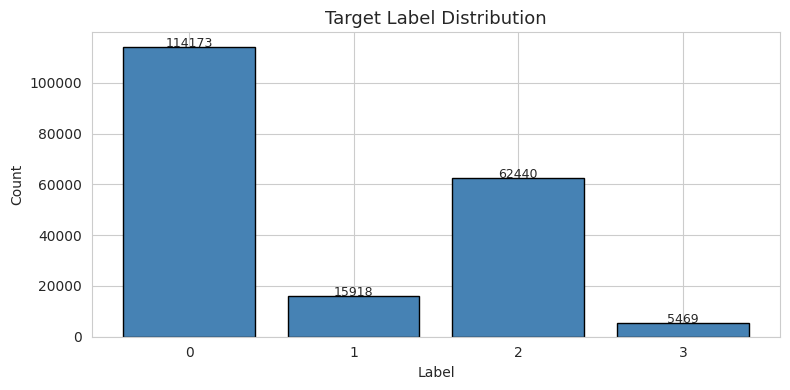

In [5]:
# ── 1. Target Distribution ──────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 4))
label_counts = train['label'].value_counts().sort_index()
bars = ax.bar(label_counts.index.astype(str), label_counts.values,
              color='steelblue', edgecolor='black')
ax.set_title('Target Label Distribution', fontsize=13)
ax.set_xlabel('Label')
ax.set_ylabel('Count')
for bar, v in zip(bars, label_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100,
            str(v), ha='center', fontsize=9)
plt.tight_layout()
plt.show()

**Insight:** The dataset is heavily imbalanced — Label 0 dominates with the most samples while Label 3 is the minority class with significantly fewer samples. This imbalance means a naive model would simply predict Label 0 most of the time, so we must use `class_weight='balanced'` to ensure all classes are learned equally.

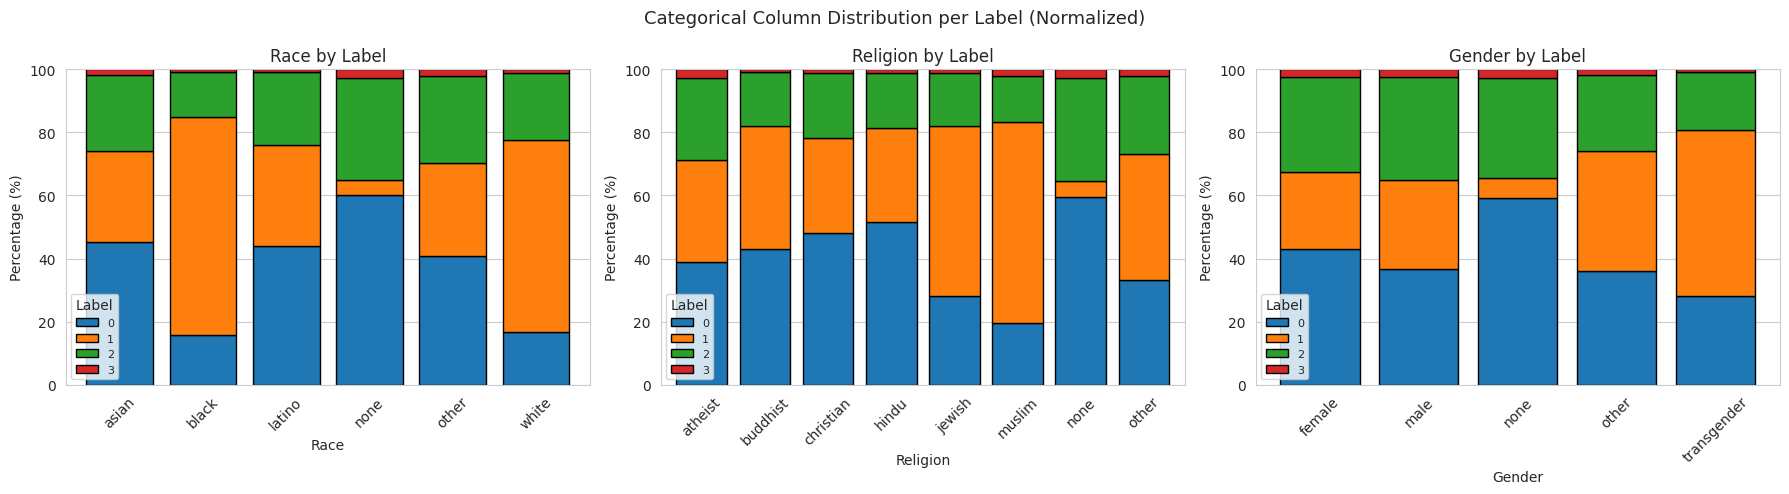

In [6]:
# ── 2. Categorical Column Analysis ──────────────────────────────────────
cat_cols = ['race', 'religion', 'gender']
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(cat_cols):
    temp = train.copy()
    temp[col] = temp[col].fillna('none').replace('0', 'none').str.lower()
    
    # Normalize to proportions
    ct = temp.groupby([col, 'label']).size().unstack(fill_value=0)
    ct = ct.div(ct.sum(axis=1), axis=0) * 100   # normalize to 100%
    
    ct.plot(kind='bar', stacked=True, ax=axes[i], edgecolor='black', width=0.8)
    axes[i].set_title(f'{col.capitalize()} by Label', fontsize=12)
    axes[i].set_xlabel(col.capitalize())
    axes[i].set_ylabel('Percentage (%)')
    axes[i].set_ylim(0, 100)
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].legend(title='Label', fontsize=8)

plt.suptitle('Categorical Column Distribution per Label (Normalized)', fontsize=13)
plt.tight_layout()
plt.show()

**Insight:** All three categorical columns (`race`, `religion`, `gender`) are heavily sparse — the majority of comments have `none` (not mentioned). This means these columns alone are weak predictors, but when a category IS mentioned it may carry a strong signal. One-Hot Encoding preserves these rare but potentially important category values.

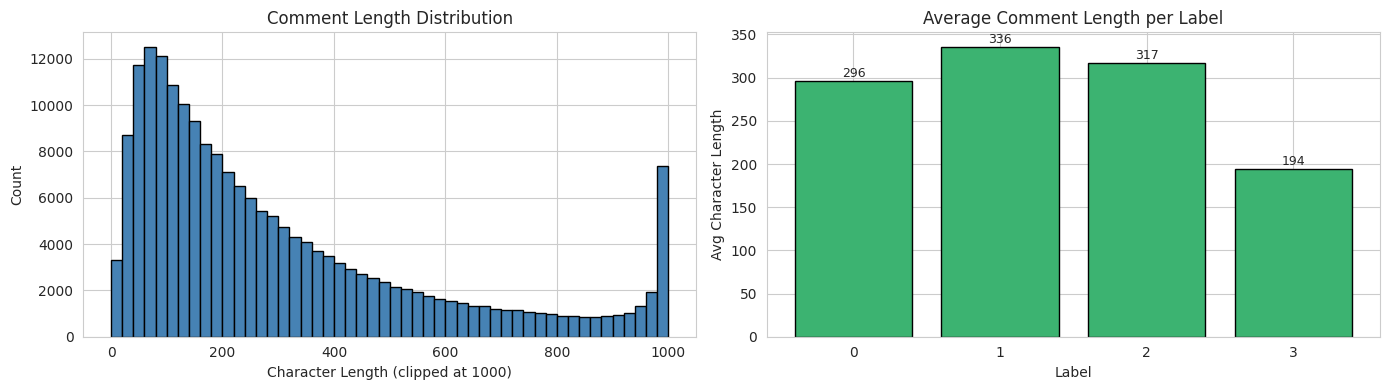

In [7]:
# ── 3. Text Data Analysis ───────────────────────────────────────────────
train['_clen'] = train['comment'].fillna('').astype(str).apply(len)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Comment length histogram
axes[0].hist(train['_clen'].clip(0, 1000), bins=50, color='steelblue', edgecolor='black')
axes[0].set_title('Comment Length Distribution', fontsize=12)
axes[0].set_xlabel('Character Length (clipped at 1000)')
axes[0].set_ylabel('Count')

# Average comment length per label
avg_len = train.groupby('label')['_clen'].mean()
axes[1].bar(avg_len.index.astype(str), avg_len.values, color='mediumseagreen', edgecolor='black')
axes[1].set_title('Average Comment Length per Label', fontsize=12)
axes[1].set_xlabel('Label')
axes[1].set_ylabel('Avg Character Length')
for i, v in enumerate(avg_len.values):
    axes[1].text(i, v + 5, f'{v:.0f}', ha='center', fontsize=9)

plt.tight_layout()
plt.show()
train.drop(columns=['_clen'], inplace=True)

**Insight:** Most comments are short — the distribution is right-skewed with a long tail of very long comments. Different label categories show noticeably different average comment lengths, confirming that `comment_length` and `word_count` are useful features. Longer comments tend to belong to specific label categories, giving the model a length-based signal.

In [9]:
# ── 4. Feature Correlation ──────────────────────────────────────────────
num_cols = ['upvote', 'downvote', 'emoticon_1', 'emoticon_2',
            'emoticon_3', 'if_1', 'if_2', 'disability', 'label']
corr = train[num_cols].fillna(0).corr()

plt.figure(figsize=(9, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, linewidths=0.5)
plt.title('Feature Correlation Heatmap', fontsize=13)
plt.tight_layout()
plt.show()

**Insight:** `if_2` shows the strongest correlation with the label (~0.23), making it the most important numeric feature in the dataset — likely a pre-engineered signal by the competition. `if_1` also shows a moderate correlation. Emoticon columns have weaker but non-zero correlations, confirming they carry some emotional signal worth keeping. Most features have low inter-correlation, meaning each contributes independent information to the model.

## 5. Key Insights from EDA

1. **Class Imbalance** — The label distribution is highly imbalanced. We handle this using `class_weight='balanced'` in all models.

2. **Comment Length varies by label** — Certain label categories tend to have longer or shorter comments, making `comment_length` and `word_count` valuable features.

3. **`if_2` has strong correlation (~0.23) with label** — This is the strongest numeric signal in the dataset, likely a pre-engineered feature by the competition.

4. **Identity columns are multi-class** — `race`, `religion`, `gender` are not boolean flags but proper categorical columns. We apply One-Hot Encoding to preserve all category information.

5. **Emoticons carry emotional signal** — Emoticon counts vary by label and represent pre-engineered platform signals worth keeping.

6. **`upvote`, `downvote`, `post_id`, `created_date` dropped** — These either leak information, are redundant after feature engineering, or carry no predictive value as raw columns.

## 6. Train / Validation Split
> ⚠️ Split happens on **raw data** before any feature engineering to prevent leakage.


In [11]:
X_raw = train.drop(columns=['label']).copy()
y     = train['label'].copy()

X_tr, X_val, y_tr, y_val = train_test_split(
    X_raw, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Train : {X_tr.shape[0]} rows")
print(f"Val   : {X_val.shape[0]} rows")

Train : 158400 rows
Val   : 39600 rows


## 7. Drop Irrelevant Columns
> Drop raw columns and all their related engineered columns.


### Why I drop the votes and time features

> **Votes feature**
> Are votes given after the label is assigned? If yes, using them would create data leakage. I also checked their correlation with the label, which supports dropping them.

> **Time feature**
> We comment based on a post's content, not the time. For ML we could still use time (busy hours, weekends), so I checked the correlation of all the time features with the label. It was almost zero.


In [12]:
drop_cols = ['upvote', 'downvote', 'created_date', 'post_id']
for df in [X_tr, X_val]:
    df.drop(columns=[c for c in drop_cols if c in df.columns], inplace=True)

test_clean = test.drop(columns=[c for c in drop_cols if c in test.columns]).copy()

print("Remaining columns:", X_tr.columns.tolist())

Remaining columns: ['emoticon_1', 'emoticon_2', 'emoticon_3', 'if_1', 'if_2', 'race', 'religion', 'gender', 'disability', 'comment']


## 8. Fill Missing Values
> - `comment` → `''` (empty string, TF-IDF expects a string)
> - `race`, `religion`, `gender` → `'none'` (a valid category meaning "not mentioned"), lowercased and stripped
> - `disability` → `0` (binary flag, missing = not mentioned)


In [13]:
def fill_missing(df):
    df['comment']  = df['comment'].fillna('').astype(str)
    for col in ['race', 'religion', 'gender']:
        df[col] = df[col].fillna('none').astype(str).str.strip().str.lower()
        df[col] = df[col].replace('0', 'none')
    df['disability'] = df['disability'].fillna(0)
    return df

X_tr       = fill_missing(X_tr)
X_val      = fill_missing(X_val)
test_clean = fill_missing(test_clean)

print("Missing values after fill:")
print(X_tr[['comment', 'race', 'religion', 'gender', 'disability']].isnull().sum())

Missing values after fill:
comment       0
race          0
religion      0
gender        0
disability    0
dtype: int64


## 9. Feature Engineering
> All features computed independently per split — no leakage.


In [14]:
def engineer_features(df):
    # ── Text stats ───────────────────────────────────────────────────────
    df['comment_length'] = df['comment'].apply(len)
    df['word_count']     = df['comment'].apply(lambda x: len(x.split()))
    df['capital_ratio']  = df['comment'].apply(
        lambda x: sum(1 for c in x if c.isupper()) / (len(x) + 1))
    df['num_punct']      = df['comment'].apply(
        lambda x: sum(1 for c in x if c in '!?.,;:'))
    df['has_url']        = df['comment'].apply(
        lambda x: 1 if 'http' in x.lower() else 0)

    # ── Emoticons ────────────────────────────────────────────────────────
    df['emoticon_total'] = df['emoticon_1'] + df['emoticon_2'] + df['emoticon_3']

    return df

X_tr       = engineer_features(X_tr)
X_val      = engineer_features(X_val)
test_clean = engineer_features(test_clean)

print("Features engineered. Train shape:", X_tr.shape)

Features engineered. Train shape: (158400, 16)


## 10. Minimal Text Cleaning
> Removing extra whitespace, URLs and other noise that doesn't carry sentiment.


In [15]:
import re

def clean_comment(text):
    text = str(text).lower()                          # lowercase
    text = re.sub(r'http\S+|www\S+', '', text)        # remove URLs
    text = re.sub(r'<.*?>', '', text)                 # remove HTML tags
    text = re.sub(r'\s+', ' ', text).strip()          # remove extra whitespace
    return text


X_tr['comment']       = X_tr['comment'].apply(clean_comment)
X_val['comment']      = X_val['comment'].apply(clean_comment)
test_clean['comment'] = test_clean['comment'].apply(clean_comment)

## 11. ColumnTransformer — TF-IDF + OneHotEncoder + StandardScaler
> A single `ColumnTransformer` handles all three transformations cleanly.
> - **TF-IDF** → `comment` column (text → sparse vector)
> - **OneHotEncoder** → `race`, `religion`, `gender` (no ordinal relationship)
> - **StandardScaler** → all numeric features (normalises scale for LR and SVM)

In [16]:
# Define feature groups
text_col     = 'comment'
cat_cols     = ['race', 'religion', 'gender']
num_cols     = [
    'emoticon_1', 'emoticon_2', 'emoticon_3', 'emoticon_total',
    'comment_length', 'word_count', 'capital_ratio', 'num_punct', 'has_url',
    'disability', 'if_1', 'if_2'
]

# ── ColumnTransformer ────────────────────────────────────────────────────
preprocessor = ColumnTransformer(transformers=[
    ('tfidf', TfidfVectorizer(
        max_features=50000,
        ngram_range=(1, 2),
        # stop_words='english',
        sublinear_tf=True,
        min_df=3
    ), text_col),
    ('onehot', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=True
    ), cat_cols),

    ('scaler', StandardScaler(), num_cols)
], remainder='drop')

# Fit on train, transform all splits
X_train_final = preprocessor.fit_transform(X_tr)
X_val_final   = preprocessor.transform(X_val)
X_test_final  = preprocessor.transform(test_clean)

print("ColumnTransformer fitted successfully.")
print(f"Train matrix : {X_train_final.shape}")
print(f"Val matrix   : {X_val_final.shape}")
print(f"Test matrix  : {X_test_final.shape}")

ColumnTransformer fitted successfully.
Train matrix : (158400, 50031)
Val matrix   : (39600, 50031)
Test matrix  : (102000, 50031)


## 12. Model Training


### Model 1 — LightGBM
> Trained with best hyperparameters from tuning + early stopping.

In [17]:
lgb = LGBMClassifier(
    n_estimators=2000,
    learning_rate=0.03,
    max_depth=5,
    num_leaves=20,
    min_child_samples=50,
    reg_alpha=0.3,
    reg_lambda=0.3,
    subsample=0.7,
    colsample_bytree=0.7,
    class_weight='balanced',
    random_state=42,
    verbosity=-1
)

lgb.fit(
    X_train_final, y_tr,
    eval_set=[(X_val_final, y_val)],
    callbacks=[
        early_stopping(stopping_rounds=50, verbose=False),
        log_evaluation(period=100)
    ]
)

print(f"Best iteration: {lgb.best_iteration_}")
lgb_preds = lgb.predict(X_val_final)
print(f"Accuracy : {accuracy_score(y_val, lgb_preds):.4f}")
print(f"Macro F1 : {f1_score(y_val, lgb_preds, average='macro'):.4f}")


[100]	valid_0's multi_logloss: 0.493552
[200]	valid_0's multi_logloss: 0.439112
[300]	valid_0's multi_logloss: 0.414973
[400]	valid_0's multi_logloss: 0.39887
[500]	valid_0's multi_logloss: 0.387152
[600]	valid_0's multi_logloss: 0.37797
[700]	valid_0's multi_logloss: 0.370582
[800]	valid_0's multi_logloss: 0.364168
[900]	valid_0's multi_logloss: 0.358797
[1000]	valid_0's multi_logloss: 0.354133
[1100]	valid_0's multi_logloss: 0.349959
[1200]	valid_0's multi_logloss: 0.346141
[1300]	valid_0's multi_logloss: 0.342823
[1400]	valid_0's multi_logloss: 0.339735
[1500]	valid_0's multi_logloss: 0.336852
[1600]	valid_0's multi_logloss: 0.334237
[1700]	valid_0's multi_logloss: 0.33175
[1800]	valid_0's multi_logloss: 0.329521
[1900]	valid_0's multi_logloss: 0.327359
[2000]	valid_0's multi_logloss: 0.325245
Best iteration: 2000
Accuracy : 0.9000
Macro F1 : 0.7896


### Model 2 — Logistic Regression
> Strong linear baseline. Benefits from `StandardScaler` applied in the pipeline.

In [18]:
lr = LogisticRegression(max_iter=2000,penalty='l2',class_weight='balanced', n_jobs=-1, random_state=42)
lr.fit(X_train_final, y_tr)
lr_preds = lr.predict(X_val_final)
print(f"Accuracy : {accuracy_score(y_val, lr_preds):.4f}")
print(f"Macro F1 : {f1_score(y_val, lr_preds, average='macro'):.4f}")


Accuracy : 0.8996
Macro F1 : 0.7986


### Model 3 — Linear SVC
> Excellent for high-dimensional sparse TF-IDF data. Very sensitive to feature scale — benefits from `StandardScaler`.

In [19]:
clf = LinearSVC(C=1.0,loss='squared_hinge',tol=1e-3,class_weight='balanced',max_iter=3000, random_state=42)
clf.fit(X_train_final, y_tr)
clf_preds = clf.predict(X_val_final)
print(f"Accuracy : {accuracy_score(y_val, clf_preds):.4f}")
print(f"Macro F1 : {f1_score(y_val, clf_preds, average='macro'):.4f}")

Accuracy : 0.7880
Macro F1 : 0.6878


## 13. Evaluation — Accuracy + Macro F1
> Tracking both metrics since competition metric is unknown.  
> - **Accuracy** — overall correctness  
> - **Macro F1** — better for imbalanced classes, treats all classes equally

In [20]:
results = {
    'LightGBM'           : lgb_preds,
    'Logistic Regression': lr_preds,
    'Linear SVC'         : clf_preds,
}

print(f"{'Model':<25} {'Accuracy':>10} {'Macro F1':>10}")
print("-" * 47)
for name, preds in results.items():
    acc = accuracy_score(y_val, preds)
    f1  = f1_score(y_val, preds, average='macro')
    print(f"{name:<25} {acc:>10.4f} {f1:>10.4f}")

print()
for name, preds in results.items():
    print(f"=== {name} — Classification Report ===")
    print(classification_report(y_val, preds))

Model                       Accuracy   Macro F1
-----------------------------------------------
LightGBM                      0.9000     0.7896
Logistic Regression           0.8996     0.7986
Linear SVC                    0.7880     0.6878

=== LightGBM — Classification Report ===
              precision    recall  f1-score   support

           0       0.98      0.95      0.96     22835
           1       0.69      0.85      0.76      3183
           2       0.90      0.84      0.87     12488
           3       0.44      0.80      0.56      1094

    accuracy                           0.90     39600
   macro avg       0.75      0.86      0.79     39600
weighted avg       0.92      0.90      0.91     39600

=== Logistic Regression — Classification Report ===
              precision    recall  f1-score   support

           0       0.98      0.93      0.96     22835
           1       0.68      0.84      0.75      3183
           2       0.88      0.86      0.87     12488
           3  

### Ensemble — LightGBM + Logistic Regression
> Soft voting: average of the two models' predicted probabilities (50/50).


In [21]:
lgb_probs      = lgb.predict_proba(X_val_final)
lr_probs       = lr.predict_proba(X_val_final)

ensemble_probs = 0.5 * lgb_probs + 0.5 * lr_probs
ensemble_preds = np.argmax(ensemble_probs, axis=1)

print(f"Ensemble Accuracy : {accuracy_score(y_val, ensemble_preds):.4f}")
print(f"Ensemble Macro F1 : {f1_score(y_val, ensemble_preds, average='macro'):.4f}")

Ensemble Accuracy : 0.9064
Ensemble Macro F1 : 0.8089


## 14. Generate Submission
> Final predictions use the LightGBM + Logistic Regression ensemble.


In [24]:
lgb_probs      = lgb.predict_proba(X_test_final)
lr_probs       = lr.predict_proba(X_test_final)

ensemble_probs = 0.5 * lgb_probs + 0.5 * lr_probs
ensemble_preds = np.argmax(ensemble_probs, axis=1)

submission = pd.read_csv("/kaggle/input/comment-category-prediction-challenge/Sample.csv")
submission['label'] = ensemble_preds

submission.to_csv("submission.csv", index=False)

print("✅ submission.csv saved!")
print("Prediction distribution:")


✅ submission.csv saved!
Prediction distribution:
